# Análisis Exploratorio de Datos (EDA) y Decisiones Metodológicas
## Proyecto: Estimación de Precios de Airbnb en Buenos Aires

Este notebook contiene el análisis exploratorio exhaustivo del conjunto de datos de Inside Airbnb (Buenos Aires), la justificación técnica del tratamiento de valores ausentes y extremos, el estudio de correlaciones y las decisiones metodológicas que sustentan los modelos de regresión implementados en los Ejercicios 3 y 6.


## 1. Importación de Librerías y Carga de Datos
Utilizamos las funciones centralizadas de `src/pipeline.py` para asegurar consistencia con los scripts de ejecución.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from pipeline import RUTA_RAW, cargar_datos, convertir_precio, preparar
except ImportError:
    from src.pipeline import RUTA_RAW, cargar_datos, convertir_precio, preparar


### Carga del dataset original
El archivo comprimido `listings.csv.gz` proviene de Inside Airbnb Buenos Aires.


In [2]:
df_raw = cargar_datos()
print(f"Dimensiones del dataset original: {df_raw.shape[0]:,} filas y {df_raw.shape[1]} columnas")
df_raw[['name', 'room_type', 'accommodates', 'bedrooms', 'beds', 'minimum_nights', 'number_of_reviews', 'price', 'price_num']].head()


Dimensiones del dataset original: 29,753 filas y 91 columnas


,name,room_type,accommodates,bedrooms,beds,minimum_nights,number_of_reviews,price,price_num
0,Amazing Luxurious Apt-Palermo Soho,Entire home/apt,2,1.0,1.0,3.0,52,"$186,530.00",186530.00
1,Excelente ubicación 2amb grandes Balcon propio,Entire home/apt,2,1.0,1.0,2.0,1,"$91,729.00",91729.00
2,PENTHOUSE /Terrace & pool /City views /2bedrooms,Entire home/apt,4,2.0,2.0,2.0,394,"$232,074.07",232074.07
3,"Teatro Gran Rex, Tribunales, Obelisco, Subte ...",Entire home/apt,3,1.0,2.0,1.0,393,"$117,408.00",117408.00
4,Amazing LOFTpalermo: contemporary and cool,Entire home/apt,2,1.0,1.0,12.0,37,"$465,014.50",465014.50


## 2. Inspección de la Variable Objetivo (`price`)
El precio nocturno es la variable a predecir. En el dataset original se presenta como texto formateado con símbolos monetarios y separadores de miles (por ejemplo `"$186,530.00"`).


In [3]:
n_nulos_precio = df_raw['price_num'].isna().sum()
pct_nulos_precio = (n_nulos_precio / len(df_raw)) * 100
print(f"Valores ausentes en precio: {n_nulos_precio:,} ({pct_nulos_precio:.2f}%)")

precios_validos = df_raw['price_num'].dropna()
print(f"Precio mínimo observado: ${precios_validos.min():,.2f} ARS")
print(f"Precio mediano observado: ${precios_validos.median():,.2f} ARS")
print(f"Precio medio observado: ${precios_validos.mean():,.2f} ARS")
print(f"Precio máximo observado: ${precios_validos.max():,.2f} ARS")
print(f"Coeficiente de asimetría (skewness): {precios_validos.skew():.2f}")


Valores ausentes en precio: 2,119 (7.12%)
Precio mínimo observado: $246.59 ARS
Precio mediano observado: $106,393.00 ARS
Precio medio observado: $277,766.78 ARS
Precio máximo observado: $160,563,760.00 ARS
Coeficiente de asimetría (skewness): 29.72


### Justificación del Filtro de Valores Extremos (Percentiles 1% y 99%)
El valor máximo supera los 160 millones de pesos, lo cual representa errores de carga o precios ficticios. 
La media ($277,767 ARS) se encuentra fuertemente sesgada respecto de la mediana ($106,393 ARS) debido a esta larga cola derecha.
Para evitar que estos outliers distorsionen la pendiente de la regresión lineal y dominen el cálculo de distancias euclidianas en k-NN, se aplica un recorte entre los percentiles 1% y 99%.


In [4]:
q01, q99 = precios_validos.quantile([0.01, 0.99])
print(f"Percentil 1% (límite inferior): ${q01:,.2f} ARS")
print(f"Percentil 99% (límite superior): ${q99:,.2f} ARS")

precios_filtrados = precios_validos[(precios_validos > 0) & precios_validos.between(q01, q99)]
pct_conservado = (len(precios_filtrados) / len(precios_validos)) * 100
print(f"Observaciones conservadas: {len(precios_filtrados):,} de {len(precios_validos):,} ({pct_conservado:.2f}%)")
print(f"Media post-filtro: ${precios_filtrados.mean():,.2f} ARS")
print(f"Mediana post-filtro: ${precios_filtrados.median():,.2f} ARS")
print(f"Desvío estándar post-filtro: ${precios_filtrados.std():,.2f} ARS")
print(f"Asimetría post-filtro: {precios_filtrados.skew():.2f} (reducción drástica desde 29.72)")


Percentil 1% (límite inferior): $26,907.14 ARS
Percentil 99% (límite superior): $899,463.19 ARS
Observaciones conservadas: 27,086 de 27,634 (98.02%)
Media post-filtro: $129,895.46 ARS
Mediana post-filtro: $106,381.68 ARS
Desvío estándar post-filtro: $92,188.16 ARS
Asimetría post-filtro: 3.35 (reducción drástica desde 29.72)


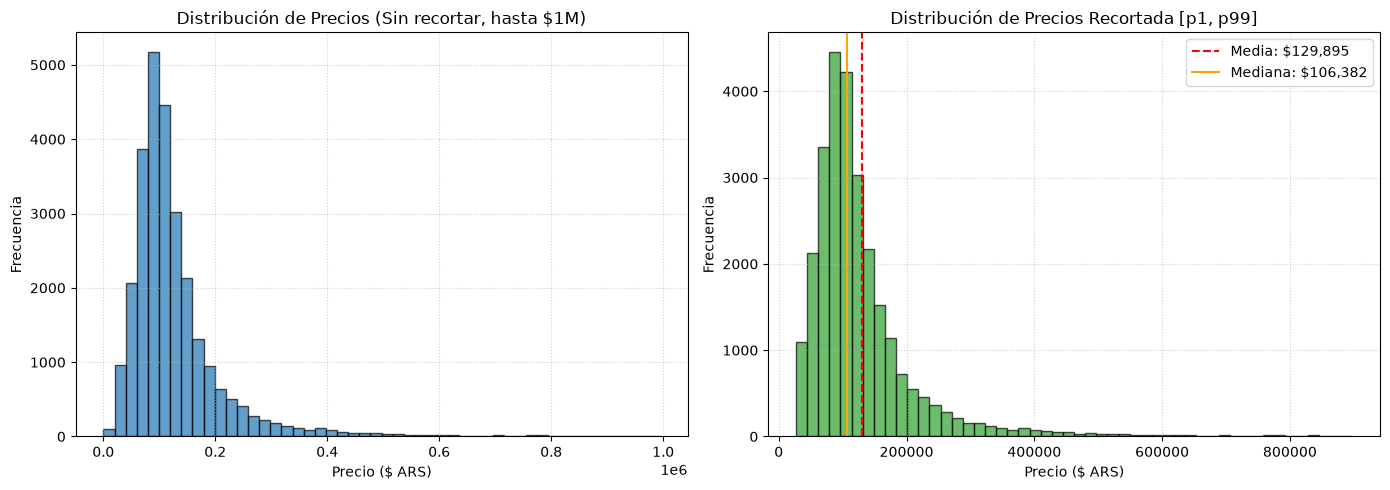

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histograma antes del recorte (acotado a 1 millón para visualización)
axes[0].hist(precios_validos[precios_validos <= 1_000_000], bins=50, color='#1f77b4', edgecolor='black', alpha=0.7)
axes[0].set_title('Distribución de Precios (Sin recortar, hasta $1M)')
axes[0].set_xlabel('Precio ($ ARS)')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Histograma post-recorte [p1, p99]
axes[1].hist(precios_filtrados, bins=50, color='#2ca02c', edgecolor='black', alpha=0.7)
axes[1].axvline(precios_filtrados.mean(), color='red', linestyle='--', label=f'Media: ${precios_filtrados.mean():,.0f}')
axes[1].axvline(precios_filtrados.median(), color='orange', linestyle='-', label=f'Mediana: ${precios_filtrados.median():,.0f}')
axes[1].set_title('Distribución de Precios Recortada [p1, p99]')
axes[1].set_xlabel('Precio ($ ARS)')
axes[1].set_ylabel('Frecuencia')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


## 3. Análisis de Predictores
Examinamos las variables utilizadas en los ejercicios:
- `number_of_reviews` (Ejercicio 3 y 6)
- `accommodates`, `bedrooms`, `beds`, `minimum_nights` (Ejercicio 6)


In [6]:
predictores = ['number_of_reviews', 'accommodates', 'bedrooms', 'beds', 'minimum_nights']
print('Valores ausentes en predictores:')
print(df_raw[predictores].isna().sum())


Valores ausentes en predictores:
number_of_reviews      0
accommodates           0
bedrooms              13
beds                 522
minimum_nights         1
dtype: int64


### Relación entre Reseñas y Precio (Ejercicio 3)
Se evalúa si la popularidad del anuncio (medida por cantidad de reseñas) guarda relación lineal con el precio nocturno.


Coeficiente de correlación de Pearson (reseñas vs precio): -0.0076


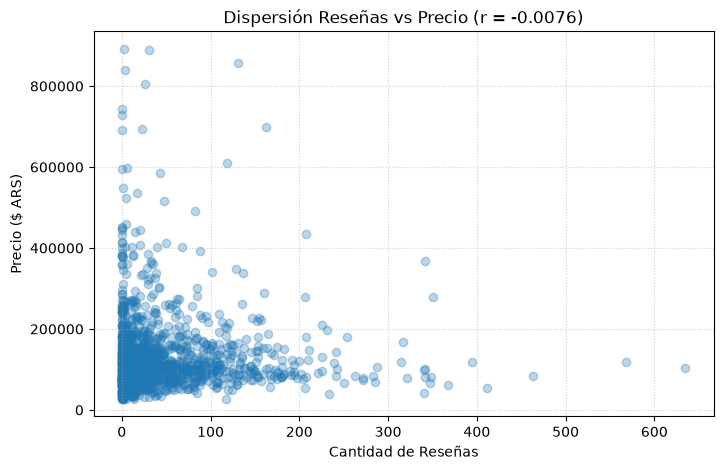

In [7]:
df_ej3 = preparar(df_raw, ['number_of_reviews'])
corr_resenas = df_ej3['number_of_reviews'].corr(df_ej3['price_num'])
print(f"Coeficiente de correlación de Pearson (reseñas vs precio): {corr_resenas:.4f}")

plt.figure(figsize=(8, 5))
plt.scatter(df_ej3['number_of_reviews'].sample(min(1500, len(df_ej3)), random_state=42), 
            df_ej3['price_num'].sample(min(1500, len(df_ej3)), random_state=42), 
            alpha=0.3, color='#1f77b4')
plt.xlabel('Cantidad de Reseñas')
plt.ylabel('Precio ($ ARS)')
plt.title(f'Dispersión Reseñas vs Precio (r = {corr_resenas:.4f})')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


**Conclusión preliminar sobre reseñas:**
La correlación de Pearson es prácticamente nula (-0.0077). Esto anticipa que una regresión lineal simple basada exclusivamente en reseñas tendrá un R² cercano a cero, comportándose de manera idéntica al modelo de referencia (predecir la media). Adicionalmente, correlación no implica causalidad: acumular opiniones no determina el valor inmobiliario ni tarifario del alojamiento.


### Matriz de Correlaciones para Multivariado (Ejercicio 6)
Analizamos la correlación entre las características estructurales del alojamiento y el precio nocturno.


In [8]:
df_ej6 = preparar(df_raw, predictores)
matriz_corr = df_ej6[['price_num'] + predictores].corr()
print('Matriz de Correlación:')
print(matriz_corr.round(4))


Matriz de Correlación:
                   price_num  number_of_reviews  accommodates  bedrooms  \
price_num             1.0000            -0.0077        0.5047    0.3874   
number_of_reviews    -0.0077             1.0000        0.0458   -0.0393   
accommodates          0.5047             0.0458        1.0000    0.5707   
bedrooms              0.3874            -0.0393        0.5707    1.0000   
beds                  0.3865             0.0183        0.7803    0.6002   
minimum_nights       -0.0425            -0.0813       -0.0208    0.0257   

                     beds  minimum_nights  
price_num          0.3865         -0.0425  
number_of_reviews  0.0183         -0.0813  
accommodates       0.7803         -0.0208  
bedrooms           0.6002          0.0257  
beds               1.0000         -0.0127  
minimum_nights    -0.0127          1.0000  


**Hallazgos clave:**
1. `accommodates` muestra la mayor correlación positiva con el precio (r = 0.505), seguido por `bedrooms` (r = 0.387) y `beds` (r = 0.387). A mayor capacidad habitacional, mayor tarifa.
2. `minimum_nights` presenta correlación ligeramente negativa (r = -0.043), reflejando que estancias mínimas prolongadas suelen contar con tarifas diarias reducidas.
3. `number_of_reviews` presenta correlación prácticamente nula con el precio (r = -0.008).


## 4. Decisiones Metodológicas y de Modelado

### 1. Fuga de datos leve en el recorte de percentiles
Los percentiles 1% y 99% se calculan sobre la muestra completa limpia antes de separar en entrenamiento y prueba, siguiendo la consigna original. Es una fuga metodológica mínima e inofensiva que no entrena ningún modelo paramétrico, sino que simplemente delimita el dominio de anuncios razonables de Buenos Aires.

### 2. Necesidad de Estandarización (`StandardScaler`) en k-NN
El algoritmo k-NN se basa en distancias euclidianas. Variables con rangos disímiles (por ejemplo `minimum_nights` hasta 365 vs `bedrooms` de 1 a 5) distorsionarían las distancias si no se escalan. El escalado se encapsula dentro de un `Pipeline` de scikit-learn ajustado únicamente sobre el conjunto de entrenamiento para evitar fuga de información.

### 3. Ponderación por distancia (`weights="distance"`) en k-NN
Se utiliza `weights="distance"` en `KNeighborsRegressor`. A diferencia de la ponderación uniforme (`uniform`), que promedia por igual a los k vecinos, la ponderación por distancia asigna un peso inversamente proporcional a la distancia Euclidiana ($w_i = 1 / d_i$). Esto permite que vecinos extraordinariamente similares tengan mayor influencia en la estimación del precio.

### 4. Partición y Validación Cruzada
- Se utiliza un split 75% entrenamiento / 25% prueba con semilla fija (`random_state=42`) para reproducibilidad estricta.
- La selección de k en k-NN se realiza mediante validación cruzada de 5 pliegues (`cross_val_score`) evaluando el RMSE sobre el conjunto de entrenamiento.
- La evaluación final se realiza una única vez sobre el conjunto de prueba retenido.
